# Deep Learning Midterm: Health Claim Verification

Comparative Analysis of Transformer Models for Health Claim Verification: Accuracy, Data Efficiency, and Error Patterns

In this notebook, I fine-tune SciBERT and DistilBERT to classify whether a piece of evidence **supports**, **refutes**, or is **neutral** toward a health-related claim. I also compare both transformers with a TF-IDF + Logistic Regression baseline.

My main experiment is to use **25%, 50%, and 100% of the training data** and see how the models respond to having more labeled examples. I use the same development and test sets throughout so the comparisons stay consistent. After training, I look at overall scores, loss curves, class-specific errors, and a sample prediction.

**Note:** The notebook saves results to Google Drive. If results from a previous run already exist, some training cells will say *Skipping completed* and load those saved results rather than training again.

## 1. Install the libraries

I start by installing the packages needed for the experiment. Hugging Face and PyTorch handle the transformer models, while scikit-learn and the other libraries help with the baseline, evaluation, and plots.

In [1]:
!pip -q install "transformers>=4.46,<5" "scikit-learn>=1.3" "pandas>=2.0" "matplotlib>=3.7" "safetensors>=0.4"

In [2]:
import torch
import transformers
import huggingface_hub

from transformers import AutoTokenizer, AutoModelForSequenceClassification

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())
print("All required imports successful!")

PyTorch: 2.11.0+cu130
Transformers: 4.57.6
Hugging Face Hub: 0.36.2
CUDA available: True
All required imports successful!


## 2. Set up the experiment

Here I import the libraries, check that Colab can see the GPU, and set the main training options. I use a fixed random seed and keep the learning rate, number of epochs, and other settings consistent across the transformer experiments.
I also connect Google Drive so the results are saved even if the Colab session ends.

In [3]:
import os, sys, json, random, hashlib, gc, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import train_test_split

SEED = 42
SMOKE_TEST = False
EPOCHS = 3 if not SMOKE_TEST else 1
MAX_LENGTH = 256
TRAIN_BATCH_SIZE = 8
EVAL_BATCH_SIZE = 16
GRAD_ACCUM_STEPS = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
FRACTIONS = [0.25, 0.50, 1.00] if not SMOKE_TEST else [0.25]
MODELS = {
    "SciBERT": "allenai/scibert_scivocab_uncased",
    "DistilBERT": "distilbert/distilbert-base-uncased",
}
LABEL_NAMES = ["SUPPORT", "REFUTE", "NEUTRAL"]
LABEL_TO_ID = {name: i for i, name in enumerate(LABEL_NAMES)}
ID_TO_LABEL = {i: name for name, i in LABEL_TO_ID.items()}

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
if not torch.cuda.is_available() and not SMOKE_TEST:
    raise RuntimeError("No GPU detected. Colab: Runtime → Change runtime type → T4 GPU.")
print("PyTorch:", torch.__version__, "Transformers:", transformers.__version__)
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/HealthVer_Midterm")
except ImportError:
    BASE_DIR = Path.cwd() / "HealthVer_Midterm"
RESULTS_DIR = BASE_DIR / ("smoke_test" if SMOKE_TEST else "final_results")
RAW_DIR = BASE_DIR / "official_data"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)
print("Results will be saved in:", RESULTS_DIR)

PyTorch: 2.11.0+cu130 Transformers: 4.57.6
Device: Tesla T4
Mounted at /content/drive
Results will be saved in: /content/drive/MyDrive/HealthVer_Midterm/final_results


## 3. Load the official HealthVer dataset

I download the original training, development, and test files from the HealthVer repository. Before doing any preprocessing, I check their sizes, column names, and a few examples so I know exactly what the model will be learning from. I also save file checksums to help keep track of the dataset version.

In [4]:
import requests
SOURCE_ROOT = "https://raw.githubusercontent.com/sarrouti/HealthVer/master/data"
FILES = {"train": "healthver_train.csv", "dev": "healthver_dev.csv", "test": "healthver_test.csv"}
raw_frames = {}
checksum_rows = []
for split, file_name in FILES.items():
    path = RAW_DIR / file_name
    if not path.exists():
        response = requests.get(f"{SOURCE_ROOT}/{file_name}", timeout=120)
        response.raise_for_status()
        path.write_bytes(response.content)
    checksum_rows.append({"split": split, "file": file_name, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
    raw_frames[split] = pd.read_csv(path)
    print(split, raw_frames[split].shape, list(raw_frames[split].columns))

pd.DataFrame(checksum_rows).to_csv(RESULTS_DIR / "dataset_sha256.csv", index=False)
display(raw_frames["train"].head(3)[["claim", "evidence", "label"]])

train (10590, 6) ['id', 'evidence', 'claim', 'label', 'topic_ip', 'question']
dev (1917, 6) ['id', 'evidence', 'claim', 'label', 'topic_ip', 'question']
test (1823, 6) ['id', 'evidence', 'claim', 'label', 'topic_ip', 'question']


,claim,evidence,label
0,Results on the use of hydroxychloroquine as a ...,HCQ should be prescribed as a part of treatmen...,Refutes
1,The good news. Properly disinfecting our homes...,"As discussed in this review, till effective va...",Neutral
2,"If you decide to engage in public activities, ...","Model simulations, using data relevant to COVI...",Supports


## 4. Clean and inspect the data

Here I prepare the claim evidence pairs, standardize the three labels, and turn the labels into numerical IDs. I check the class distribution because an uneven number of examples can make accuracy alone misleading. I also inspect duplicates and overlap between data splits so I can mention any limitations when interpreting the results.

Kept 10590/10590; removed 0 missing/blank rows
Kept 1917/1917; removed 0 missing/blank rows
Kept 1823/1823; removed 0 missing/blank rows
Class distribution:


,train,dev,test
label_name,,,
SUPPORT,3782,533,671
REFUTE,2411,391,425
NEUTRAL,4397,993,727


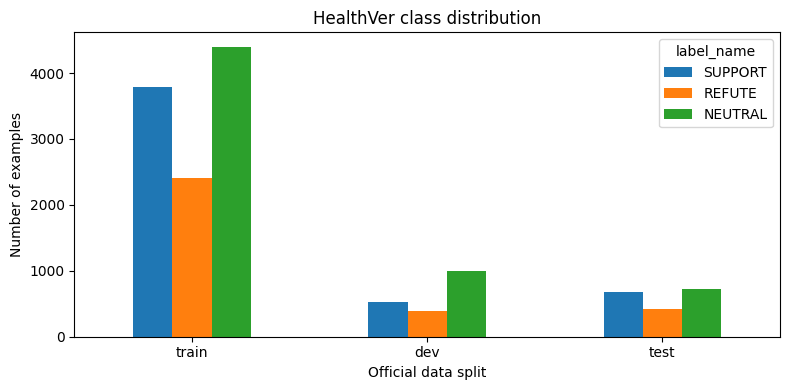

train vs dev: exact shared pairs=9; shared claim texts=1
train vs test: exact shared pairs=0; shared claim texts=1
dev vs test: exact shared pairs=0; shared claim texts=0
train duplicate claim–evidence pairs: 700
dev duplicate claim–evidence pairs: 198
test duplicate claim–evidence pairs: 129


In [5]:
def normalize_label(value):
    value = str(value).strip().lower()
    mapping = {
        "supports": "SUPPORT", "support": "SUPPORT", "supported": "SUPPORT",
        "refutes": "REFUTE", "refute": "REFUTE", "contradict": "REFUTE", "contradicts": "REFUTE",
        "neutral": "NEUTRAL", "nei": "NEUTRAL",
    }
    if value not in mapping:
        raise ValueError(f"Unrecognized label: {value!r}. Inspect the original dataset CSV.")
    return mapping[value]

def prepare(raw):
    required = {"claim", "evidence", "label"}
    if not required.issubset(raw.columns):
        raise ValueError(f"Missing expected fields {required - set(raw.columns)}")
    df = raw.copy()
    before = len(df)
    df = df.dropna(subset=["claim", "evidence", "label"]).copy()
    df["claim"] = df["claim"].astype(str).str.strip()
    df["evidence"] = df["evidence"].astype(str).str.strip()
    df = df[(df["claim"].str.len() > 0) & (df["evidence"].str.len() > 0)].copy()
    df["label_name"] = df["label"].map(normalize_label)
    df["label_id"] = df["label_name"].map(LABEL_TO_ID).astype(int)
    print(f"Kept {len(df)}/{before}; removed {before-len(df)} missing/blank rows")
    return df.reset_index(drop=True)

train_df = prepare(raw_frames["train"])
dev_df   = prepare(raw_frames["dev"])
test_df  = prepare(raw_frames["test"])

summary = pd.DataFrame({
    split: df["label_name"].value_counts().reindex(LABEL_NAMES, fill_value=0)
    for split, df in [("train", train_df), ("dev", dev_df), ("test", test_df)]
})
print("Class distribution:")
display(summary)
summary.to_csv(RESULTS_DIR / "class_distribution.csv")

fig, ax = plt.subplots(figsize=(8,4))
summary.T.plot(kind="bar", ax=ax)
ax.set_ylabel("Number of examples")
ax.set_xlabel("Official data split")
ax.set_title("HealthVer class distribution")
plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "class_distribution.png", dpi=180); plt.show()

def text_key(s):
    return str(s).strip().casefold()

def keys(df, kind="pair"):
    if kind == "pair":
        return set(zip(df.claim.map(text_key), df.evidence.map(text_key)))
    return set(df.claim.map(text_key))

for name_a, df_a, name_b, df_b in [("train",train_df,"dev",dev_df), ("train",train_df,"test",test_df), ("dev",dev_df,"test",test_df)]:
    shared_pairs = len(keys(df_a,"pair") & keys(df_b,"pair"))
    shared_claims = len(keys(df_a,"claim") & keys(df_b,"claim"))
    print(f"{name_a} vs {name_b}: exact shared pairs={shared_pairs}; shared claim texts={shared_claims}")

for split, df in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
    print(f"{split} duplicate claim–evidence pairs:", int(df.duplicated(["claim","evidence"]).sum()))
    df.to_csv(RESULTS_DIR / f"prepared_{split}.csv", index=False)

## 5. Create the 25%, 50%, and 100% training sets

I create three versions of the training set to study data efficiency. I keep the class proportions approximately the same and make the smaller subsets part of the larger ones. The development and test data stay unchanged, so any score changes are easier to relate to the amount of training data.

In [6]:
all_idx = np.arange(len(train_df))
idx_50, _ = train_test_split(all_idx, train_size=0.50, random_state=SEED, stratify=train_df.label_id)
idx_25, _ = train_test_split(idx_50, train_size=0.50, random_state=SEED, stratify=train_df.iloc[idx_50].label_id)
SUBSET_INDEX = {0.25: np.sort(idx_25), 0.50: np.sort(idx_50), 1.00: all_idx}
SUBSETS = {fraction: train_df.iloc[ids].reset_index(drop=True) for fraction, ids in SUBSET_INDEX.items()}
for fraction, part in SUBSETS.items():
    print(f"{int(fraction*100)}%: {len(part)} examples; label counts = {part.label_name.value_counts().to_dict()}")
    part.to_csv(RESULTS_DIR / f"training_subset_{int(fraction*100)}pct.csv", index=False)

25%: 2647 examples; label counts = {'NEUTRAL': 1099, 'SUPPORT': 945, 'REFUTE': 603}
50%: 5295 examples; label counts = {'NEUTRAL': 2199, 'SUPPORT': 1891, 'REFUTE': 1205}
100%: 10590 examples; label counts = {'NEUTRAL': 4397, 'SUPPORT': 3782, 'REFUTE': 2411}


## 6. Train a traditional machine learning baseline

Before comparing transformers, I train a simpler reference model using TF-IDF features and Logistic Regression. This tells me how far word and phrase patterns alone can go on the task. I run it at each training data fraction and save its test predictions and evaluation scores.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import joblib

def make_text(df):
    return ("claim: " + df["claim"] + " evidence: " + df["evidence"]).tolist()

def metrics_from_preds(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=list(range(3)), average="macro", zero_division=0)
    return {"accuracy": float(accuracy_score(y_true, y_pred)), "precision_macro": float(p), "recall_macro": float(r), "macro_f1": float(f1)}

def save_predictions(df, y_pred, name, fraction):
    out = df[["claim", "evidence", "label_name", "label_id"]].copy()
    out["pred_id"] = np.asarray(y_pred, dtype=int)
    out["pred_label"] = out["pred_id"].map(ID_TO_LABEL)
    out["correct"] = out.label_id == out.pred_id
    out.to_csv(RESULTS_DIR / f"predictions_{name}_{int(fraction*100)}pct.csv", index=False)
    return out

results_file = RESULTS_DIR / "all_results.csv"
results = pd.read_csv(results_file).to_dict("records") if results_file.exists() else []
for fraction in FRACTIONS:
    if any(str(r["model"]) == "TFIDF_LR" and abs(float(r["fraction"]) - fraction) < 1e-6 for r in results):
        print(f"Skipping completed TF-IDF+LR {fraction:.0%}")
        continue
    subset = SUBSETS[fraction]
    baseline = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=50000, sublinear_tf=True)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=SEED))
    ])
    start = time.perf_counter()
    baseline.fit(make_text(subset), subset.label_id)
    duration = time.perf_counter() - start
    test_pred = baseline.predict(make_text(test_df))
    score = metrics_from_preds(test_df.label_id, test_pred)
    score.update({"model": "TFIDF_LR", "fraction": fraction, "n_train": len(subset), "training_seconds": round(duration,2), "best_epoch": None})
    results.append(score)
    save_predictions(test_df, test_pred, "TFIDF_LR", fraction)
    print(f"TF-IDF+LR | {fraction:.0%} | Macro-F1={score['macro_f1']:.4f} | Acc={score['accuracy']:.4f}")
    if fraction == 1.00:
        joblib.dump(baseline, RESULTS_DIR / "baseline_tfidf_lr_100pct.joblib")


pd.DataFrame(results).to_csv(RESULTS_DIR / "all_results.csv", index=False)

Skipping completed TF-IDF+LR 25%
Skipping completed TF-IDF+LR 50%
Skipping completed TF-IDF+LR 100%


## 7. Inspect SciBERT and DistilBERT

Here I load the pretrained model configurations and tokenizers, then inspect details such as the number of layers, attention heads, and hidden dimensions. I also look at how a claim and its evidence become tokens. This helps connect the architecture discussed in class with the actual input the model receives.

In [8]:
from transformers import AutoConfig, AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, get_linear_schedule_with_warmup
from torch.utils.data import Dataset, DataLoader

for name, checkpoint in MODELS.items():
    cfg = AutoConfig.from_pretrained(checkpoint)
    print(name, "| type:", cfg.model_type,
          "| layers:", getattr(cfg, "num_hidden_layers", getattr(cfg,"n_layers", "?")),
          "| hidden dimension:", getattr(cfg, "hidden_size", getattr(cfg,"dim", "?")),
          "| attention heads:", getattr(cfg, "num_attention_heads", getattr(cfg,"n_heads", "?")))

tok_demo = AutoTokenizer.from_pretrained(MODELS["SciBERT"])
ex = train_df.iloc[0]
encoded = tok_demo(ex.claim, ex.evidence, truncation=True, max_length=MAX_LENGTH)
print("\nExample label:", ex.label_name)
print("Example claim:", ex.claim[:140])
print("Token IDs, first 25:", encoded["input_ids"][:25])
print("Tokens, first 25:", tok_demo.convert_ids_to_tokens(encoded["input_ids"][:25]))
print("Attention mask, first 25:", encoded["attention_mask"][:25])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

SciBERT | type: bert | layers: 12 | hidden dimension: 768 | attention heads: 12


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

DistilBERT | type: distilbert | layers: 6 | hidden dimension: 768 | attention heads: 12


vocab.txt: 0.00B [00:00, ?B/s]


Example label: REFUTE
Example claim: Results on the use of hydroxychloroquine as a treatment for Covid-19 have shown no significant differences in health outcomes between the co
Token IDs, first 25: [102, 545, 191, 111, 626, 131, 15513, 27782, 14313, 30107, 188, 106, 922, 168, 21004, 173, 579, 371, 360, 817, 425, 684, 1595, 121, 947]
Tokens, first 25: ['[CLS]', 'results', 'on', 'the', 'use', 'of', 'hydroxy', '##chloro', '##quin', '##e', 'as', 'a', 'treatment', 'for', 'cov', '##id', '-', '19', 'have', 'shown', 'no', 'significant', 'differences', 'in', 'health']
Attention mask, first 25: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 8. Define the transformer fine-tuning process

This cell sets up how SciBERT and DistilBERT will be trained. It creates batches of tokenized claim evidence pairs, calculates cross-entropy loss, and uses backpropagation and AdamW optimizer to update the weights. After each epoch, I evaluate on the development set and keep the checkpoint with the **highest development Macro-F1**, which is not necessarily the one with the lowest development loss.

In [9]:
from contextlib import nullcontext

class PairDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=256):
        self.enc = tokenizer(df.claim.tolist(), df.evidence.tolist(), truncation=True,
                             max_length=max_length, padding=False)
        self.targets = df.label_id.astype(int).tolist()
    def __len__(self):
        return len(self.targets)
    def __getitem__(self, idx):
        row = {key: values[idx] for key, values in self.enc.items()}
        row["labels"] = self.targets[idx]
        return row

def get_loader(df, tokenizer, batch_size, shuffle=False):
    collator = DataCollatorWithPadding(tokenizer=tokenizer, padding="longest", pad_to_multiple_of=8)
    return DataLoader(PairDataset(df, tokenizer, MAX_LENGTH), batch_size=batch_size,
                      shuffle=shuffle, collate_fn=collator, num_workers=2, pin_memory=torch.cuda.is_available())

def predict_model(model, loader, device):
    model.eval()
    losses, targets, predictions = [], [], []
    with torch.inference_mode():
        for batch in loader:
            batch = {k: v.to(device) for k,v in batch.items()}
            out = model(**batch)
            losses.append(float(out.loss.item()))
            predictions.extend(out.logits.argmax(dim=1).cpu().numpy().tolist())
            targets.extend(batch["labels"].cpu().numpy().tolist())
    return float(np.mean(losses)), np.asarray(targets), np.asarray(predictions)

def train_transformer(display_name, checkpoint, fraction):
    set_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    subset = SUBSETS[fraction]
    if SMOKE_TEST:
        subset = subset.head(48).copy()
        dev_eval = dev_df.head(48).copy()
        test_eval = test_df.head(48).copy()
    else:
        dev_eval, test_eval = dev_df, test_df
    tokenizer = AutoTokenizer.from_pretrained(checkpoint)
    train_loader = get_loader(subset, tokenizer, TRAIN_BATCH_SIZE, shuffle=True)
    dev_loader = get_loader(dev_eval, tokenizer, EVAL_BATCH_SIZE)
    test_loader = get_loader(test_eval, tokenizer, EVAL_BATCH_SIZE)
    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint, num_labels=3, id2label=ID_TO_LABEL, label2id=LABEL_TO_ID).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"\nTraining {display_name} ({fraction:.0%}) | examples={len(subset)} | parameters={n_params:,}")
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    total_updates = ((len(train_loader) + GRAD_ACCUM_STEPS - 1) // GRAD_ACCUM_STEPS) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1*total_updates), num_training_steps=total_updates)
    amp_enabled = (device.type == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
    best_score, best_epoch, best_state = -1, None, None
    epoch_rows = []
    start = time.perf_counter()
    for epoch in range(1, EPOCHS+1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        epoch_losses = []
        for step, batch in enumerate(train_loader):
            batch = {k: v.to(device) for k,v in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_enabled):
                outputs = model(**batch)
                loss = outputs.loss
                adjusted_loss = loss / GRAD_ACCUM_STEPS
            scaler.scale(adjusted_loss).backward()
            epoch_losses.append(loss.item())
            if (step+1) % GRAD_ACCUM_STEPS == 0 or (step+1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)
        val_loss, y_val, pred_val = predict_model(model, dev_loader, device)
        val_macro_f1 = f1_score(y_val, pred_val, labels=[0,1,2], average="macro", zero_division=0)
        epoch_rows.append({"epoch":epoch, "train_loss":float(np.mean(epoch_losses)),
                           "val_loss":val_loss, "val_macro_f1":float(val_macro_f1)})
        print(f"  epoch {epoch}/{EPOCHS} | train loss {np.mean(epoch_losses):.4f} | dev loss {val_loss:.4f} | dev Macro-F1 {val_macro_f1:.4f}")
        if val_macro_f1 > best_score:
            best_score, best_epoch = float(val_macro_f1), epoch
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

    model.load_state_dict(best_state)
    del best_state
    val_loss, y_val, pred_val = predict_model(model, dev_loader, device)
    test_loss, y_test, pred_test = predict_model(model, test_loader, device)
    score = metrics_from_preds(y_test, pred_test)
    score.update({"model":display_name, "fraction":fraction, "n_train":len(subset),
                  "training_seconds":round(time.perf_counter()-start,2), "best_epoch":best_epoch,
                  "dev_macro_f1":best_score, "test_loss":test_loss, "parameters":n_params})
    save_predictions(test_eval, pred_test, display_name, fraction)
    history = pd.DataFrame(epoch_rows)
    history.to_csv(RESULTS_DIR / f"history_{display_name}_{int(fraction*100)}pct.csv", index=False)
    if fraction == 1.00 and not SMOKE_TEST:
        checkpoint_dir = RESULTS_DIR / f"checkpoint_{display_name}_100pct"
        model.save_pretrained(checkpoint_dir)
        tokenizer.save_pretrained(checkpoint_dir)
        print("Saved final checkpoint:", checkpoint_dir)
    fig, ax = plt.subplots(figsize=(7,4))
    ax.plot(history.epoch, history.train_loss, marker="o", label="Training loss")
    ax.plot(history.epoch, history.val_loss, marker="o", label="Development loss")
    ax.set_title(f"{display_name} | {int(fraction*100)}% training data")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy loss")
    ax.legend(); ax.grid(alpha=.2)
    plt.tight_layout()
    fig.savefig(RESULTS_DIR / f"loss_{display_name}_{int(fraction*100)}pct.png",dpi=180)
    plt.show(); plt.close(fig)
    print(f"  TEST: Macro-F1={score['macro_f1']:.4f}; Accuracy={score['accuracy']:.4f}")
    del model, optimizer, scheduler, train_loader, dev_loader, test_loader
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return score

## 9. Run the transformer experiments

I now fine-tune SciBERT and DistilBERT with each of the three training-data sizes. Together with the traditional baseline, this gives me nine experiments. Each run saves its predictions, training history, and scores; if a run was already completed, the notebook skips it instead of repeating the training.

In [10]:
results_file = RESULTS_DIR / "all_results.csv"
if results_file.exists():
    results = pd.read_csv(results_file).to_dict("records")
else:
    results = []

def already_done(model_name, fraction):
    return any(str(r["model"]) == model_name and abs(float(r["fraction"]) - fraction) < 1e-6
               for r in results)

for model_name, checkpoint in MODELS.items():
    for fraction in FRACTIONS:
        if already_done(model_name, fraction):
            print(f"Skipping completed: {model_name} {fraction:.0%}")
            continue
        row = train_transformer(model_name, checkpoint, fraction)
        results.append(row)
        pd.DataFrame(results).to_csv(results_file, index=False)
        print("Checkpointed results to", results_file)
print("All requested transformer experiments finished.")

Skipping completed: SciBERT 25%
Skipping completed: SciBERT 50%
Skipping completed: SciBERT 100%
Skipping completed: DistilBERT 25%
Skipping completed: DistilBERT 50%
Skipping completed: DistilBERT 100%
All requested transformer experiments finished.


## 10. Compare the models and training-data sizes

Here I put the saved results into one table and create the data-efficiency graph. I'm mainly looking for two things: which model performs best and whether adding more labeled examples helps each model. I use Macro-F1 alongside accuracy because I want to consider all three classes rather than focusing only on the most common one.

,model,fraction,n_train,accuracy,precision_macro,recall_macro,macro_f1,training_seconds,best_epoch
6,DistilBERT,0.25,2647,0.5612,0.5393,0.5346,0.5358,99.33,3.0
7,DistilBERT,0.50,5295,0.6034,0.5865,0.5909,0.5877,141.59,3.0
8,DistilBERT,1.00,10590,0.6769,0.6681,0.6651,0.6664,228.38,3.0
3,SciBERT,0.25,2647,0.6654,0.6440,0.6453,0.6437,166.96,3.0
4,SciBERT,0.50,5295,0.7153,0.7004,0.7002,0.6976,257.44,2.0
5,SciBERT,1.00,10590,0.7614,0.7484,0.7469,0.7475,413.98,2.0
0,TFIDF_LR,0.25,2647,0.5869,0.5640,0.5459,0.5448,0.82,NaN
1,TFIDF_LR,0.50,5295,0.6330,0.6115,0.5961,0.5974,1.69,NaN
2,TFIDF_LR,1.00,10590,0.6643,0.6457,0.6293,0.6322,5.42,NaN


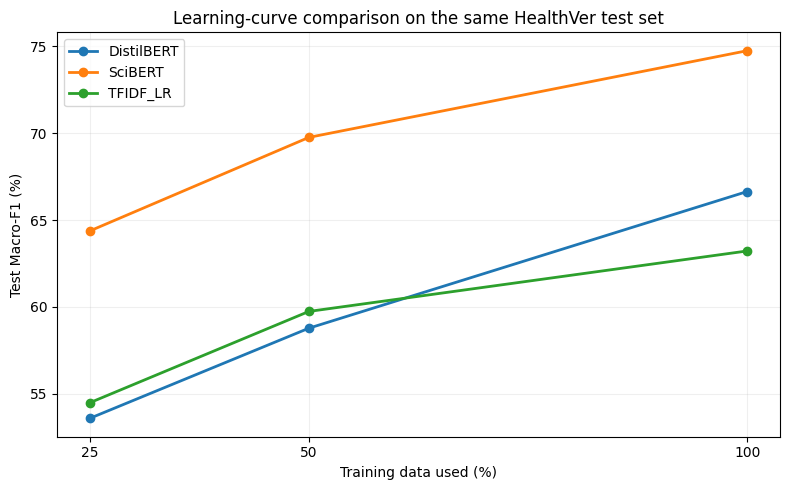

In [11]:
results_df = pd.read_csv(RESULTS_DIR / "all_results.csv")
cols = ["model","fraction","n_train","accuracy","precision_macro","recall_macro","macro_f1","training_seconds","best_epoch"]
display(results_df[cols].sort_values(["model","fraction"]).round(4))

fig, ax = plt.subplots(figsize=(8,5))
for name, group in results_df.groupby("model"):
    group = group.sort_values("fraction")
    ax.plot(group.fraction*100, group.macro_f1*100, marker="o", linewidth=2, label=name)
ax.set_xticks([25,50,100])
ax.set_xlabel("Training data used (%)")
ax.set_ylabel("Test Macro-F1 (%)")
ax.set_title("Learning-curve comparison on the same HealthVer test set")
ax.legend(); ax.grid(alpha=.2)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "data_efficiency_macro_f1.png",dpi=180)
plt.show(); plt.close(fig)

## 11. Look beyond overall accuracy

In this cell, I generate a classification report and confusion matrix for each model trained on the full dataset. These show where the models make mistakes, Ex: whether REFUTE is harder to recognize than SUPPORT or NEUTRAL. This gives me more useful information than one overall score.


 TFIDF_LR


,precision,recall,f1-score,support
SUPPORT,0.597,0.690,0.640,671.000
REFUTE,0.564,0.407,0.473,425.000
NEUTRAL,0.777,0.791,0.784,727.000
accuracy,0.664,0.664,0.664,0.664
macro avg,0.646,0.629,0.632,1823.000
weighted avg,0.661,0.664,0.658,1823.000


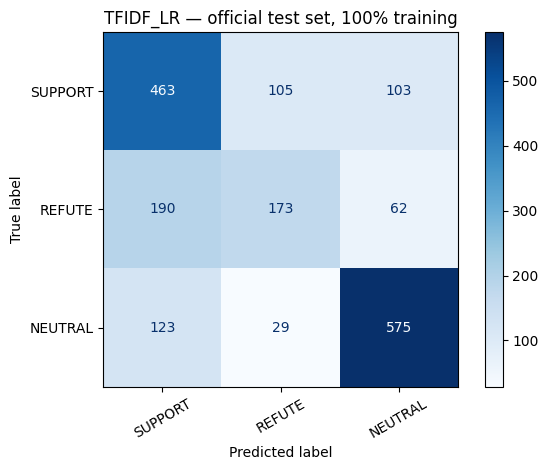


 SciBERT


,precision,recall,f1-score,support
SUPPORT,0.743,0.775,0.759,671.000
REFUTE,0.667,0.654,0.660,425.000
NEUTRAL,0.836,0.812,0.823,727.000
accuracy,0.761,0.761,0.761,0.761
macro avg,0.748,0.747,0.747,1823.000
weighted avg,0.762,0.761,0.762,1823.000


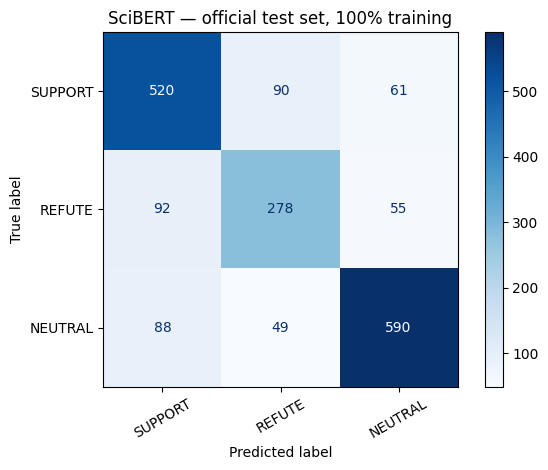


 DistilBERT


,precision,recall,f1-score,support
SUPPORT,0.640,0.669,0.654,671.000
REFUTE,0.616,0.593,0.604,425.000
NEUTRAL,0.749,0.733,0.741,727.000
accuracy,0.677,0.677,0.677,0.677
macro avg,0.668,0.665,0.666,1823.000
weighted avg,0.678,0.677,0.677,1823.000


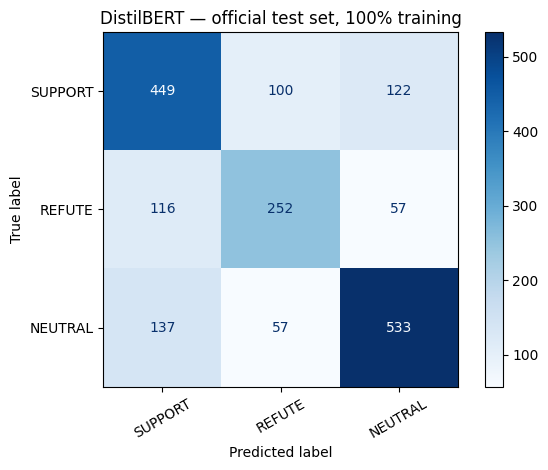

In [12]:
if 1.00 not in FRACTIONS:
    print("SMOKE_TEST only: skip this cell until full experiments complete.")
else:
    for name in ["TFIDF_LR", "SciBERT", "DistilBERT"]:
        path = RESULTS_DIR / f"predictions_{name}_100pct.csv"
        if not path.exists():
            print("Not finished yet:", path)
            continue
        dfp = pd.read_csv(path)
        print("\n", name)
        report = classification_report(dfp.label_id, dfp.pred_id,
                    labels=[0,1,2], target_names=LABEL_NAMES, zero_division=0, output_dict=True)
        display(pd.DataFrame(report).T.round(3))
        pd.DataFrame(report).T.to_csv(RESULTS_DIR / f"class_report_{name}.csv")
        cm = confusion_matrix(dfp.label_id, dfp.pred_id, labels=[0,1,2])
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABEL_NAMES)
        disp.plot(values_format="d", cmap="Blues", xticks_rotation=30)
        plt.title(f"{name} — official test set, 100% training")
        plt.tight_layout()
        plt.savefig(RESULTS_DIR / f"confusion_{name}.png",dpi=180)
        plt.show(); plt.close()

## 12. Review examples that SciBERT classified incorrectly

I take a fixed sample of 50 errors from the full data SciBERT predictions. Reading the actual claims and evidence helps me look for possible patterns behind the mistakes, such as evidence that is related to a topic but does not directly answer the claim. I treat these as observations from individual examples, not proof of a general cause.

In [13]:
candidate = RESULTS_DIR / "predictions_SciBERT_100pct.csv"
if candidate.exists():
    errors = pd.read_csv(candidate)
    errors = errors[~errors.correct.astype(bool)].copy()
    errors = errors.sample(n=min(50,len(errors)), random_state=SEED)
    errors.to_csv(RESULTS_DIR / "SciBERT_50_sample_errors_to_review.csv",index=False)
    print("Sampled errors:", len(errors))
    display(errors[["claim","evidence","label_name","pred_label"]].head(12))
else:
    print("Run the full SciBERT experiment first (100% training).")

Sampled errors: 50


,claim,evidence,label_name,pred_label
1104,Wearing a surgical face mask probably won't ke...,and 3) provides suggestion that the public sho...,SUPPORT,REFUTE
310,The N95 respirator is thicker than a surgical ...,Surgical face masks significantly reduced dete...,NEUTRAL,REFUTE
439,"Covid-19 hits the old hardest, and young peopl...",A confirmed SARS-CoV-2 infection substantially...,NEUTRAL,REFUTE
982,UVC wands kill viruses. They're also a 'major ...,Most alcohol based hand sanitizers are effecti...,NEUTRAL,REFUTE
1303,N95 masks are more effective than regular masks.,Our simple model shows that modest efficacy of...,NEUTRAL,SUPPORT
1324,Surgical Masks Stop Transmission Of COVID-19 F...,The patient was transported to operating theat...,REFUTE,SUPPORT
1166,nearly half of coronavirus cases are people 20...,We estimate an overall infection fatality rate...,NEUTRAL,SUPPORT
319,the warmer weather will slow the spread of SAR...,it seems that high levels of urban air polluti...,REFUTE,SUPPORT
1477,Diabetes is generally known to weaken the immu...,Type 2 diabetic patients were more susceptible...,SUPPORT,NEUTRAL
1656,it is safe take Advil to bring down your tempe...,CONCLUSIONS: In this cohort of COVID-19 patien...,SUPPORT,REFUTE


## 13. Try the saved SciBERT model on a new example

To make the project more concrete, I load the saved SciBERT checkpoint and give it a claim and an evidence passage. The model outputs its predicted relationship and softmax scores. These scores describe the model's output for the supplied text, they should not be treated as verified probabilities of medical truth.

In [14]:
full_path = RESULTS_DIR / "checkpoint_SciBERT_100pct"
if full_path.exists():
    model = AutoModelForSequenceClassification.from_pretrained(full_path)
    tokenizer = AutoTokenizer.from_pretrained(full_path)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device).eval()

    def verify_claim(claim, evidence):
        encoded = tokenizer(claim, evidence, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
        encoded = {key: val.to(device) for key,val in encoded.items()}
        with torch.no_grad():
            probabilities = torch.softmax(model(**encoded).logits, dim=-1)[0].cpu().numpy()
        idx = int(probabilities.argmax())
        print("Predicted relation:", ID_TO_LABEL[idx])
        print("Softmax scores (NOT calibrated probabilities of medical truth):",
              {ID_TO_LABEL[i]: round(float(p),3) for i,p in enumerate(probabilities)})
        return ID_TO_LABEL[idx]

    verify_claim("Handwashing can reduce infectious disease transmission.",
                 "Hand hygiene reduces the risk of transferring infectious agents between people.")
else:
    print("Train SciBERT with 100% of the training data first.")

Predicted relation: SUPPORT
Softmax scores (NOT calibrated probabilities of medical truth): {'SUPPORT': 0.993, 'REFUTE': 0.005, 'NEUTRAL': 0.002}


## 14. Save the experiment settings

Finally, I record the main settings used in the experiments, including the random seed, model names, training fractions, and learning rate. Saving these details alongside the results makes it easier to explain exactly how I ran the project and to repeat the setup if needed.

In [15]:
config = {
  "seed": SEED, "smoke_test": SMOKE_TEST, "epochs": EPOCHS, "max_length": MAX_LENGTH,
  "train_batch_size": TRAIN_BATCH_SIZE, "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
  "effective_training_batch_size": TRAIN_BATCH_SIZE*GRAD_ACCUM_STEPS,
  "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
  "fractions": FRACTIONS, "models": MODELS, "label_to_id": LABEL_TO_ID,
  "split_files": FILES, "pytorch": torch.__version__, "transformers": transformers.__version__,
  "device": str(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"),
  "selection_metric": "development macro_f1", "test_split": "official test; unchanged",
}
with open(RESULTS_DIR/"experiment_config.json","w") as f:
    json.dump(config, f, indent=2)
print("Finished. All outputs are in:", RESULTS_DIR)
print("Files:")
for p in sorted(RESULTS_DIR.glob("*")):
    print(" -", p.name)

Finished. All outputs are in: /content/drive/MyDrive/HealthVer_Midterm/final_results
Files:
 - SciBERT_50_sample_errors_to_review.csv
 - all_results.csv
 - baseline_tfidf_lr_100pct.joblib
 - checkpoint_DistilBERT_100pct
 - checkpoint_SciBERT_100pct
 - class_distribution.csv
 - class_distribution.png
 - class_report_DistilBERT.csv
 - class_report_SciBERT.csv
 - class_report_TFIDF_LR.csv
 - confusion_DistilBERT.png
 - confusion_SciBERT.png
 - confusion_TFIDF_LR.png
 - data_efficiency_macro_f1.png
 - dataset_sha256.csv
 - experiment_config.json
 - history_DistilBERT_100pct.csv
 - history_DistilBERT_25pct.csv
 - history_DistilBERT_50pct.csv
 - history_SciBERT_100pct.csv
 - history_SciBERT_25pct.csv
 - history_SciBERT_50pct.csv
 - loss_DistilBERT_100pct.png
 - loss_DistilBERT_25pct.png
 - loss_DistilBERT_50pct.png
 - loss_SciBERT_100pct.png
 - loss_SciBERT_25pct.png
 - loss_SciBERT_50pct.png
 - predictions_DistilBERT_100pct.csv
 - predictions_DistilBERT_25pct.csv
 - predictions_DistilBERT_5

## 15. Plot SciBERT's training and development loss

I use the saved training history from the **100% SciBERT run** to make a clearer loss graph for the report. I'm interested in how training loss keeps falling while development loss rises, even though the checkpoint chosen using development Macro-F1 comes from epoch 2. This is a useful example of why improving training loss does not always mean improving generalization.

Columns: ['epoch', 'train_loss', 'val_loss', 'val_macro_f1']


,epoch,train_loss,val_loss,val_macro_f1
0,1,0.718080,0.681081,0.677827
1,2,0.298571,0.769763,0.722232
2,3,0.153640,0.940635,0.702214


Using columns:
epoch_col = epoch
train_loss_col = train_loss
val_loss_col = val_loss


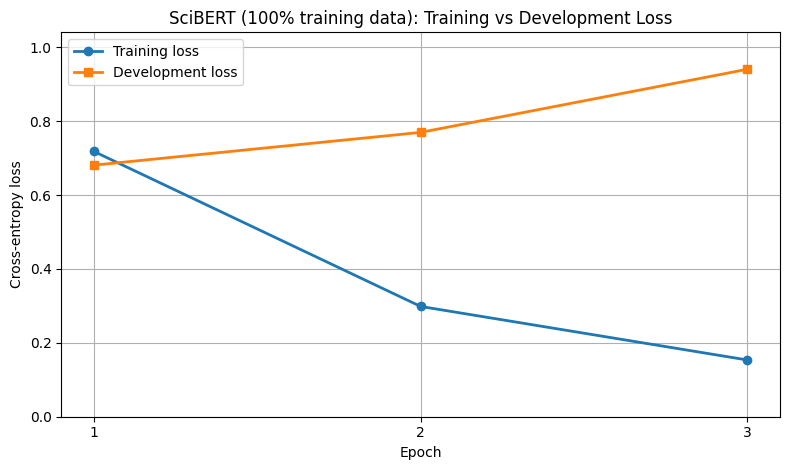

Saved file: scibert_100pct_loss_curve.png


In [16]:
import pandas as pd
import matplotlib.pyplot as plt


hist = pd.read_csv(RESULTS_DIR / "history_SciBERT_100pct.csv")


print("Columns:", hist.columns.tolist())
display(hist)


epoch_col = None
train_loss_col = None
val_loss_col = None

for c in hist.columns:
    cl = c.lower()
    if epoch_col is None and "epoch" in cl:
        epoch_col = c
    if train_loss_col is None and ("train_loss" in cl or ("loss" in cl and "eval" not in cl and "val" not in cl and "dev" not in cl)):
        train_loss_col = c
    if val_loss_col is None and (("eval_loss" in cl) or ("val_loss" in cl) or ("dev_loss" in cl) or ("validation_loss" in cl)):
        val_loss_col = c

print("Using columns:")
print("epoch_col =", epoch_col)
print("train_loss_col =", train_loss_col)
print("val_loss_col =", val_loss_col)

# Plot
plt.figure(figsize=(8, 4.8))
plt.plot(hist[epoch_col], hist[train_loss_col], marker='o', linewidth=2, label='Training loss')
plt.plot(hist[epoch_col], hist[val_loss_col], marker='s', linewidth=2, label='Development loss')

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("SciBERT (100% training data): Training vs Development Loss")
plt.xticks(hist[epoch_col])
plt.ylim(0, max(hist[val_loss_col].max(), hist[train_loss_col].max()) + 0.1)
plt.grid(True)
plt.legend()


plt.tight_layout()
plt.savefig("scibert_100pct_loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved file: scibert_100pct_loss_curve.png")